In [1]:
# from src.baseline.qwen3 import init_model
# from pathlib import Path
# from typing import List, Dict, Any
# import statistics
# import json


# def read_jsonl_file(path: Path) -> List[Dict[str, Any]]:
#     with path.open('r', encoding='utf-8') as f:
#         return [json.loads(line) for line in f if line.strip()]


# tokenizer, model = init_model("Qwen/Qwen3-0.6B")


from pathlib import Path
from typing import List, Dict, Any
import statistics
import json

from transformers import AutoTokenizer

from infer import (
    load_records,
    load_prompt_templates,
    build_messages_for_record,
)

tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen3-0.6B",
    trust_remote_code=True,
)

single_turn_system, single_turn_user = load_prompt_templates()

d:\GitHub\text2sql_distillation_draft\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# # benchmark_dir = Path("benchmarks") / "spider_data" / "format_data"
# # benchmark_dir = Path("benchmarks_2") / "spider_syn" / "format_data"
# # benchmark_dir = Path("benchmarks_2") / "spider_realistic" / "format_data"
# benchmark_dir = Path("benchmarks_2") / "spider_dk" / "format_data"

# # raw_train_data = read_jsonl_file(benchmark_dir / "train.jsonl")
# # raw_dev_data = read_jsonl_file(benchmark_dir / "dev.jsonl")
# raw_test_data = read_jsonl_file(benchmark_dir / "test.jsonl")



raw_dev_data = load_records(
    benchmark="bird",
    split="dev",
    db_filter="full",
    limit=None,
)

len(raw_dev_data), raw_dev_data[0].keys()

(1534,
 dict_keys(['benchmark', 'split', 'sample_id', 'db_id', 'question', 'gold_sql', 'schema', 'is_dialog', 'dialog_id', 'turn_index']))

In [3]:
# def get_prompt_text(tokenizer, system_prompt: str, user_prompt: str, enable_thinking: bool = False) -> str:
#     messages = [
#         {"role": "system", "content": system_prompt},
#         {"role": "user", "content": user_prompt},
#     ]
#     text = tokenizer.apply_chat_template(
#         messages,
#         tokenize=False,
#         add_generation_prompt=True,
#         enable_thinking=enable_thinking,
#     )
#     return text


# def token_length(tokenizer, text: str, model_device=None) -> int:
#     inputs = tokenizer(text, return_tensors="pt")
#     if model_device is not None:
#         inputs = inputs.to(model_device)
#     return inputs["input_ids"].shape[-1]


# def summarize_lengths(lengths: List[int]) -> Dict[str, Any]:
#     if not lengths:
#         return {}

#     lengths_sorted = sorted(lengths)
#     n = len(lengths_sorted)

#     def percentile(p: float) -> float:
#         if n == 1:
#             return lengths_sorted[0]
#         idx = (n - 1) * p
#         low = int(idx)
#         high = min(low + 1, n - 1)
#         frac = idx - low
#         return lengths_sorted[low] * (1 - frac) + lengths_sorted[high] * frac

#     return {
#         "count": n,
#         "min": min(lengths_sorted),
#         "max": max(lengths_sorted),
#         "mean": sum(lengths_sorted) / n,
#         "median": statistics.median(lengths_sorted),
#         "p50": percentile(0.50),
#         "p90": percentile(0.90),
#         "p95": percentile(0.95),
#         "p99": percentile(0.99),
#     }



def get_prompt_text(tokenizer, messages, enable_thinking: bool = False) -> str:
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=enable_thinking,
        )
    except TypeError:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )


def token_length(tokenizer, text: str) -> int:
    inputs = tokenizer(text, return_tensors="pt")
    return inputs["input_ids"].shape[-1]


def summarize_lengths(lengths: List[int]) -> Dict[str, Any]:
    return {
        "count": len(lengths),
        "min": min(lengths),
        "max": max(lengths),
        "mean": statistics.mean(lengths),
        "median": statistics.median(lengths),
        "p90": sorted(lengths)[int(0.90 * (len(lengths) - 1))],
        "p95": sorted(lengths)[int(0.95 * (len(lengths) - 1))],
        "p99": sorted(lengths)[int(0.99 * (len(lengths) - 1))],
    }

In [4]:
# from tqdm.auto import tqdm


# def analyze_dataset_token_lengths(
#     dataset: List[Dict[str, Any]],
#     tokenizer,
#     enable_thinking: bool = False,
# ):
#     prompt_lengths = []
#     prompt_plus_response_lengths = []
#     response_only_lengths = []

#     results = []

#     for i, item in tqdm(enumerate(dataset), total=len(dataset)):
#         prompt_text = get_prompt_text(
#             tokenizer=tokenizer,
#             system_prompt=item["system_prompt"],
#             user_prompt=item["user_prompt"],
#             enable_thinking=enable_thinking,
#         )
#         response_text = item["response"]

#         prompt_len = token_length(tokenizer, prompt_text)
#         full_text = prompt_text + response_text
#         full_len = token_length(tokenizer, full_text)
#         response_len = full_len - prompt_len

#         prompt_lengths.append(prompt_len)
#         prompt_plus_response_lengths.append(full_len)
#         response_only_lengths.append(response_len)

#         results.append({
#             "idx": i,
#             "prompt_len": prompt_len,
#             "prompt_plus_response_len": full_len,
#             "response_len_only": response_len,
#         })

#     summary = {
#         "prompt_only": summarize_lengths(prompt_lengths),
#         "response_only": summarize_lengths(response_only_lengths),
#         "prompt_plus_response": summarize_lengths(prompt_plus_response_lengths),
#     }

#     return results, summary


from tqdm.auto import tqdm


def analyze_dataset_token_lengths(
    dataset: List[Dict[str, Any]],
    tokenizer,
    enable_thinking: bool = False,
):
    prompt_lengths = []
    prompt_plus_response_lengths = []
    response_only_lengths = []
    results = []

    for i, record in tqdm(enumerate(dataset), total=len(dataset)):
        messages = build_messages_for_record(
            record,
            single_turn_system=single_turn_system,
            single_turn_user=single_turn_user,
        )

        prompt_text = get_prompt_text(
            tokenizer=tokenizer,
            messages=messages,
            enable_thinking=enable_thinking,
        )

        # BIRD gold field đã được infer.load_records map từ field "SQL".
        # Không dùng evidence.
        response_text = json.dumps(
            {"sql": record["gold_sql"] or ""},
            ensure_ascii=False,
        )

        prompt_len = token_length(tokenizer, prompt_text)
        full_len = token_length(tokenizer, prompt_text + response_text)
        response_len = full_len - prompt_len

        prompt_lengths.append(prompt_len)
        prompt_plus_response_lengths.append(full_len)
        response_only_lengths.append(response_len)

        results.append(
            {
                "idx": i,
                "sample_id": record["sample_id"],
                "db_id": record["db_id"],
                "question": record["question"],
                "prompt_len": prompt_len,
                "prompt_plus_response_len": full_len,
                "response_len_only": response_len,
            }
        )

    summary = {
        "prompt_only": summarize_lengths(prompt_lengths),
        "response_only": summarize_lengths(response_only_lengths),
        "prompt_plus_response": summarize_lengths(prompt_plus_response_lengths),
    }

    return results, summary

In [5]:
# results, summary = analyze_dataset_token_lengths(raw_test_data, tokenizer, enable_thinking=False)
# # results, summary = analyze_dataset_token_lengths(raw_dev_data, tokenizer, enable_thinking=False)
# # results, summary = analyze_dataset_token_lengths(raw_train_data, tokenizer, enable_thinking=False)


results, summary = analyze_dataset_token_lengths(
    raw_dev_data,
    tokenizer,
    enable_thinking=False,
)

100%|██████████| 1534/1534 [00:09<00:00, 167.77it/s]


In [6]:
summary


{'prompt_only': {'count': 1534,
  'min': 329,
  'max': 1482,
  'mean': 626.2672750977836,
  'median': 576.0,
  'p90': 752,
  'p95': 1454,
  'p99': 1463},
 'response_only': {'count': 1534,
  'min': 12,
  'max': 546,
  'mean': 56.46414602346806,
  'median': 53.0,
  'p90': 82,
  'p95': 92,
  'p99': 146},
 'prompt_plus_response': {'count': 1534,
  'min': 361,
  'max': 1628,
  'mean': 682.7314211212516,
  'median': 603.0,
  'p90': 837,
  'p95': 1503,
  'p99': 1543}}

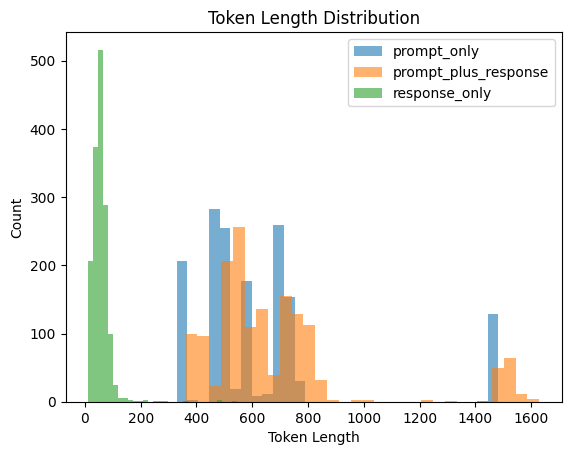

In [7]:
import matplotlib.pyplot as plt

prompt_lens = [x["prompt_len"] for x in results]
full_lens = [x["prompt_plus_response_len"] for x in results]
response_lens = [x["response_len_only"] for x in results]

plt.figure()
plt.hist(prompt_lens, bins=30, alpha=0.6, label="prompt_only")
plt.hist(full_lens, bins=30, alpha=0.6, label="prompt_plus_response")
plt.hist(response_lens, bins=30, alpha=0.6, label="response_only")

plt.xlabel("Token Length")
plt.ylabel("Count")
plt.title("Token Length Distribution")
plt.legend()

plt.show()



In [8]:
sorted(results, key=lambda x: x["prompt_plus_response_len"], reverse=True)[:10]


[{'idx': 1041,
  'sample_id': 'bird:dev:1041',
  'db_id': 'european_football_2',
  'question': 'For the teams with normal build-up play dribbling class in 2014, List the names of the teams with less than average chance creation passing, in descending order of chance creation passing.',
  'prompt_len': 1477,
  'prompt_plus_response_len': 1628,
  'response_len_only': 151},
 {'idx': 1115,
  'sample_id': 'bird:dev:1115',
  'db_id': 'european_football_2',
  'question': "What percentage is Landon Donovan's overall rating higher than Jordan Bowery on 2013/7/12?",
  'prompt_len': 1463,
  'prompt_plus_response_len': 1618,
  'response_len_only': 155},
 {'idx': 1076,
  'sample_id': 'bird:dev:1076',
  'db_id': 'european_football_2',
  'question': 'What is the difference of the average ball control score between Abdou Diallo and Aaron Appindangoye\n?',
  'prompt_len': 1461,
  'prompt_plus_response_len': 1607,
  'response_len_only': 146},
 {'idx': 1036,
  'sample_id': 'bird:dev:1036',
  'db_id': 'eu